# 🛡️ AE-WGAN NSL-KDD — Reproduction fidèle du code original GitHub

### Architecture originale (BiGAN hybride) :
1. **Generator** : 20→40→80→120→160→24, tout relu
2. **Encoder** : Flatten→Dense(20,relu)→Dense(32,linear)
3. **Discriminator** : concatenate([z,img])→Dense(80,relu)→Dense(40,relu)→Dense(1,sigmoid)
4. **Données reshapées en images 4×6×1**
5. **Ratio 1:1**, pas de gradient penalty
6. **Wasserstein loss** : K.mean(y_true * y_pred)
7. **Adamax** lr=0.00009, 101 epochs, batch_size=32

In [1]:
from google.colab import drive
drive.mount('/content/drive')
!pip install -q tensorflow numpy pandas scikit-learn matplotlib scipy

Mounted at /content/drive


In [2]:
import os, urllib.request, time
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras.layers import (Input, Dense, Reshape, Flatten, Concatenate)
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras import backend as K
from tensorflow.keras import layers
from tensorflow.keras.optimizers import Adam

from sklearn.preprocessing import OrdinalEncoder, MinMaxScaler, LabelEncoder
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score,
                             recall_score, f1_score)
from sklearn.metrics.pairwise import cosine_similarity
from scipy.spatial.distance import cdist

import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

print(f"TensorFlow: {tf.__version__}")
print(f"GPU: {tf.config.list_physical_devices('GPU')}")

TensorFlow: 2.20.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 1. Preprocessing NSL-KDD

In [3]:
url = "https://raw.githubusercontent.com/defcom17/NSL_KDD/master/"
for fname, furl in {"KDDTrain+.txt": url+"KDDTrain%2B.txt", "KDDTest+.txt": url+"KDDTest%2B.txt"}.items():
    if not os.path.exists(fname):
        urllib.request.urlretrieve(furl, fname)
        print(f"✅ {fname}")

NSL_KDD_COLUMNS = [
    'duration','protocol_type','service','flag','src_bytes','dst_bytes',
    'land','wrong_fragment','urgent','hot','num_failed_logins','logged_in',
    'num_compromised','root_shell','su_attempted','num_root',
    'num_file_creations','num_shells','num_access_files','num_outbound_cmds',
    'is_host_login','is_guest_login','count','srv_count','serror_rate',
    'srv_serror_rate','rerror_rate','srv_rerror_rate','same_srv_rate',
    'diff_srv_rate','srv_diff_host_rate','dst_host_count','dst_host_srv_count',
    'dst_host_same_srv_rate','dst_host_diff_srv_rate',
    'dst_host_same_src_port_rate','dst_host_srv_diff_host_rate',
    'dst_host_serror_rate','dst_host_srv_serror_rate',
    'dst_host_rerror_rate','dst_host_srv_rerror_rate',
    'label','difficulty_level'
]

NSL_KDD_ATTACK_MAP = {
    'normal':'Normal',
    'back':'DoS','land':'DoS','neptune':'DoS','pod':'DoS',
    'smurf':'DoS','teardrop':'DoS','mailbomb':'DoS','apache2':'DoS',
    'processtable':'DoS','udpstorm':'DoS',
    'satan':'Probe','ipsweep':'Probe','nmap':'Probe','portsweep':'Probe',
    'mscan':'Probe','saint':'Probe',
    'guess_passwd':'R2L','ftp_write':'R2L','imap':'R2L','phf':'R2L',
    'multihop':'R2L','warezmaster':'R2L','warezclient':'R2L','spy':'R2L',
    'xlock':'R2L','xsnoop':'R2L','snmpguess':'R2L','snmpgetattack':'R2L',
    'httptunnel':'R2L','sendmail':'R2L','named':'R2L','worm':'R2L',
    'buffer_overflow':'U2R','loadmodule':'U2R','rootkit':'U2R',
    'perl':'U2R','sqlattack':'U2R','xterm':'U2R','ps':'U2R',
}

df_train = pd.read_csv("KDDTrain+.txt", header=None, names=NSL_KDD_COLUMNS)
df_test = pd.read_csv("KDDTest+.txt", header=None, names=NSL_KDD_COLUMNS)
df_train = df_train.drop(columns=['difficulty_level'])
df_test = df_test.drop(columns=['difficulty_level'])
df_train['label'] = df_train['label'].str.strip().str.rstrip('.')
df_test['label'] = df_test['label'].str.strip().str.rstrip('.')

y_train_cat = df_train['label'].map(NSL_KDD_ATTACK_MAP).fillna('Unknown')
y_test_cat = df_test['label'].map(NSL_KDD_ATTACK_MAP).fillna('Unknown')
y_train_detail = df_train['label'].copy()

X_train_df = df_train.drop(columns=['label'])
X_test_df = df_test.drop(columns=['label'])

removed = []
for col in X_train_df.columns:
    if X_train_df[col].nunique() <= 1:
        removed.append(col); continue
    if X_train_df[col].value_counts(normalize=True).iloc[0] >= 0.99:
        removed.append(col)
X_train_df = X_train_df.drop(columns=removed)
X_test_df = X_test_df.drop(columns=removed, errors='ignore')

cat_cols = X_train_df.select_dtypes(include=['object']).columns.tolist()
enc = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)
X_train_df[cat_cols] = enc.fit_transform(X_train_df[cat_cols])
X_test_df[cat_cols] = enc.transform(X_test_df[cat_cols])
feature_names = X_train_df.columns.tolist()

scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train_df.values)
X_test_scaled = scaler.transform(X_test_df.values)

le_a = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)
y_enc = le_a.fit_transform(y_train_cat.values.reshape(-1,1)).ravel()
selector = SelectKBest(score_func=f_classif, k=24)
X_train_final = selector.fit_transform(X_train_scaled, y_enc)
X_test_final = selector.transform(X_test_scaled)
INPUT_DIM = 24

print(f"✅ Preprocessing: Train {X_train_final.shape}, Test {X_test_final.shape}")
print(f"Distribution: {dict(y_train_cat.value_counts())}")

✅ KDDTrain+.txt
✅ KDDTest+.txt
✅ Preprocessing: Train (125973, 24), Test (22544, 24)
Distribution: {'Normal': np.int64(67343), 'DoS': np.int64(45927), 'Probe': np.int64(11656), 'R2L': np.int64(995), 'U2R': np.int64(52)}


## 2. AE-WGAN — Reproduction exacte du code GitHub

In [4]:
class AEWGAN_Original:
    def __init__(self):
        self.img_rows = 4
        self.img_cols = 6
        self.channels = 1
        self.img_shape = (self.img_rows, self.img_cols, self.channels)
        self.latent_dim = 32
        self.flat_dim = int(np.prod(self.img_shape))  # = 24, converti en int Python

        optimizer = tf.keras.optimizers.Adamax(0.00009)

        # Build Discriminator
        self.discriminator = self._build_discriminator()
        self.discriminator.compile(
            loss=self._wasserstein_loss,
            optimizer=optimizer,
            metrics=['accuracy']
        )

        # Build Generator & Encoder
        self.generator = self._build_generator()
        self.encoder = self._build_encoder()

        # Combined model
        self.discriminator.trainable = False

        z = Input(shape=(self.latent_dim,))
        img_ = self.generator(z)

        img = Input(shape=self.img_shape)
        z_ = self.encoder(img)

        fake = self.discriminator([z, img_])
        valid = self.discriminator([z_, img])

        self.combined = Model([z, img], [fake, valid])
        self.combined.compile(
            loss=[self._wasserstein_loss, self._wasserstein_loss],
            optimizer=optimizer
        )

    def _wasserstein_loss(self, y_true, y_pred):
        return K.mean(y_true * y_pred)

    def _build_encoder(self):
        model = Sequential([
            Flatten(input_shape=self.img_shape),
            Dense(20, activation='relu'),
            Dense(self.latent_dim),
        ])
        img = Input(shape=self.img_shape)
        z = model(img)
        return Model(img, z, name='encoder')

    def _build_generator(self):
        model = Sequential([
            Dense(20, input_dim=self.latent_dim, activation='relu'),
            Dense(40, activation='relu'),
            Dense(80, activation='relu'),
            Dense(120, activation='relu'),
            Dense(160, activation='relu'),
            Dense(self.flat_dim, activation='relu'),
            Reshape(self.img_shape),
        ])
        z = Input(shape=(self.latent_dim,))
        gen_img = model(z)
        return Model(z, gen_img, name='generator')

    def _build_discriminator(self):
        z = Input(shape=(self.latent_dim,))
        img = Input(shape=self.img_shape)
        d_in = Concatenate()([z, Flatten()(img)])
        x = Dense(80, activation='relu')(d_in)
        x = Dense(40, activation='relu')(x)
        validity = Dense(1, activation='sigmoid')(x)
        return Model([z, img], validity, name='discriminator')

    def train(self, X_attack_2d, epochs=101, batch_size=32, verbose=1):
        reshaped = X_attack_2d.reshape(-1, self.img_rows, self.img_cols, self.channels)
        n_samples = reshaped.shape[0]
        if n_samples < batch_size:
            batch_size = max(n_samples // 2, 2)

        valid = np.ones((batch_size, 1))
        fake = np.zeros((batch_size, 1))

        for epoch in range(epochs):
            # Train Discriminator
            z = np.random.normal(0, 1, size=(batch_size, self.latent_dim))
            imgs_ = self.generator.predict(z, verbose=0)

            idx = np.random.randint(0, n_samples, batch_size)
            imgs = reshaped[idx]
            z_ = self.encoder.predict(imgs, verbose=0)

            d_loss_real = self.discriminator.train_on_batch([z_, imgs], valid)
            d_loss_fake = self.discriminator.train_on_batch([z, imgs_], fake)
            d_loss = 0.5 * np.add(d_loss_real, d_loss_fake)

            # Train Generator + Encoder
            g_loss = self.combined.train_on_batch([z, imgs], [valid, fake])

            if verbose and (epoch + 1) % max(1, epochs // 5) == 0:
                print(f"      Epoch {epoch+1}/{epochs} — "
                      f"D loss: {d_loss[0]:.4f}, D acc: {100*d_loss[1]:.1f}%, "
                      f"G loss: {g_loss[0]:.4f}")

    def generate(self, n):
        generated = []
        for _ in range(n):
            noise = np.random.normal(size=(32, self.latent_dim))
            gen_imgs = self.generator.predict(noise, verbose=0)
            generated.append(gen_imgs[0])
        generated = np.array(generated)
        return generated.reshape(-1, self.img_rows * self.img_cols)

print("✅ AEWGAN_Original défini")

✅ AEWGAN_Original défini


## 3. Oversampling AE-WGAN

In [5]:
print("=" * 60)
print("AE-WGAN OVERSAMPLING (architecture originale GitHub)")
print("=" * 60)

all_attack_types = sorted(y_train_detail.unique())
print(f"Types à traiter: {len(all_attack_types)}")

MIN_SAMPLES = 20
EPOCHS = 101
BATCH_SIZE = 32

all_synthetic_X = []
all_synthetic_y = []
trained_models = {}

start_time = time.time()

for attack_name in all_attack_types:
    mask = y_train_detail == attack_name
    X_attack = X_train_final[mask]
    n_orig = X_attack.shape[0]

    if n_orig < MIN_SAMPLES:
        print(f"\n  [{attack_name}] ⏭️ Sauté ({n_orig} < {MIN_SAMPLES})")
        continue

    print(f"\n  [{attack_name}] 🧠 Training ({n_orig} samples)...")

    model = AEWGAN_Original()

    bs = min(BATCH_SIZE, max(n_orig // 2, 2))
    model.train(X_attack, epochs=EPOCHS, batch_size=bs, verbose=1)

    # Code original: génère N + 20000 samples
    n_to_generate = n_orig + 20000
    print(f"  [{attack_name}] Génération de {n_to_generate} samples...")
    synthetic = model.generate(n_to_generate)

    all_synthetic_X.append(synthetic)
    all_synthetic_y.extend([attack_name] * n_to_generate)
    trained_models[attack_name] = model

    print(f"  [{attack_name}] ✅ Terminé")

elapsed = (time.time() - start_time) / 60
print(f"\n--- {elapsed:.1f} minutes ---")

# Combiner original + synthétique
X_synthetic_all = np.vstack(all_synthetic_X)
y_synthetic_all = pd.Series(all_synthetic_y)
X_augmented = np.vstack([X_train_final, X_synthetic_all])
y_augmented_detail = pd.concat([y_train_detail, y_synthetic_all], ignore_index=True)
y_augmented_cat = y_augmented_detail.map(NSL_KDD_ATTACK_MAP).fillna('Unknown')

print(f"\n{'='*60}")
print(f"  Original:    {X_train_final.shape[0]}")
print(f"  Synthétique: {X_synthetic_all.shape[0]}")
print(f"  Total:       {X_augmented.shape[0]}")
print(f"{'='*60}")

AE-WGAN OVERSAMPLING (architecture originale GitHub)
Types à traiter: 23

  [back] 🧠 Training (956 samples)...
      Epoch 20/101 — D loss: 0.2612, D acc: 60.6%, G loss: 0.5214
      Epoch 40/101 — D loss: 0.2592, D acc: 61.0%, G loss: 0.5182
      Epoch 60/101 — D loss: 0.2586, D acc: 62.0%, G loss: 0.5125
      Epoch 80/101 — D loss: 0.2582, D acc: 62.8%, G loss: 0.5084
      Epoch 100/101 — D loss: 0.2581, D acc: 63.1%, G loss: 0.5069
  [back] Génération de 20956 samples...
  [back] ✅ Terminé

  [buffer_overflow] 🧠 Training (30 samples)...
      Epoch 20/101 — D loss: 0.2582, D acc: 52.2%, G loss: 0.5668
      Epoch 40/101 — D loss: 0.2572, D acc: 54.9%, G loss: 0.5546
      Epoch 60/101 — D loss: 0.2566, D acc: 55.0%, G loss: 0.5538
      Epoch 80/101 — D loss: 0.2565, D acc: 55.6%, G loss: 0.5511
      Epoch 100/101 — D loss: 0.2560, D acc: 55.8%, G loss: 0.5480
  [buffer_overflow] Génération de 20030 samples...
  [buffer_overflow] ✅ Terminé

  [ftp_write] ⏭️ Sauté (8 < 20)

  [gu

## 4. Évaluation qualité générative

In [6]:
def compute_cosine_sim(X_real, X_synth):
    real_mean = X_real.mean(axis=0).reshape(1, -1)
    synth_mean = X_synth.mean(axis=0).reshape(1, -1)
    return cosine_similarity(real_mean, synth_mean)[0, 0]

def discrimination_test(X_real, X_synth):
    n = min(len(X_real), len(X_synth), 5000)
    X_r = X_real[np.random.choice(len(X_real), n, replace=n > len(X_real))]
    X_s = X_synth[np.random.choice(len(X_synth), n, replace=n > len(X_synth))]
    X_c = np.vstack([X_r, X_s])
    y_c = np.array([1]*n + [0]*n)
    X_tr, X_te, y_tr, y_te = train_test_split(X_c, y_c, test_size=0.3, random_state=42, stratify=y_c)
    clf = RandomForestClassifier(100, random_state=42, n_jobs=-1)
    clf.fit(X_tr, y_tr)
    return accuracy_score(y_te, clf.predict(X_te))

print(f"{'─'*70}")
print(f"  {'Attaque':<20} {'N orig':>7} {'N gen':>7} {'Cos Sim':>8} {'Disc Acc':>10} {'Qualité':>10}")
print(f"{'─'*70}")

for attack_name, model in trained_models.items():
    mask = y_train_detail == attack_name
    X_real = X_train_final[mask]
    if len(X_real) < 20:
        continue
    X_synth = model.generate(min(len(X_real), 500))
    cos_s = compute_cosine_sim(X_real, X_synth)
    disc = discrimination_test(X_real, X_synth)
    quality = "Excellent" if disc < 0.55 else "Good" if disc < 0.65 else "Fair" if disc < 0.75 else "Poor"
    print(f"  {attack_name:<20} {len(X_real):>7} {len(X_real)+20000:>7} {cos_s:>8.4f} {disc:>9.2%} {quality:>10}")

print(f"{'─'*70}")

──────────────────────────────────────────────────────────────────────
  Attaque               N orig   N gen  Cos Sim   Disc Acc    Qualité
──────────────────────────────────────────────────────────────────────
  back                     956   20956   0.3197   100.00%       Poor
  buffer_overflow           30   20030   0.1232   100.00%       Poor
  guess_passwd              53   20053   0.6489   100.00%       Poor
  ipsweep                 3599   23599   0.3495   100.00%       Poor
  neptune                41214   61214   0.1746   100.00%       Poor
  nmap                    1493   21493   0.3123   100.00%       Poor
  normal                 67343   87343   0.1645   100.00%       Poor
  pod                      201   20201   0.4411   100.00%       Poor
  portsweep               2931   22931   0.2899    99.67%       Poor
  satan                   3633   23633   0.5328   100.00%       Poor
  smurf                   2646   22646   0.5340   100.00%       Poor
  teardrop                 89

## 5. Classifieurs (Table 4 du paper)

In [7]:
def build_dt(nc=2):
    return DecisionTreeClassifier(max_depth=7 if nc==2 else 9, random_state=42)

def build_rf(nc=2):
    return RandomForestClassifier(100, max_depth=8 if nc==2 else 10, random_state=42, n_jobs=-1)

def build_cnn(dim, nc=2):
    out = 1 if nc==2 else nc
    act = 'sigmoid' if nc==2 else 'softmax'
    m = Sequential([
        layers.Input(shape=(dim,1)),
        layers.Conv1D(40,3,activation='relu',padding='same'),
        layers.Dropout(0.1), layers.Flatten(),
        layers.Dense(40,activation='relu'),
        layers.Dense(out,activation=act)
    ], name='CNN')
    m.compile(optimizer=Adam(1e-3),
              loss='binary_crossentropy' if nc==2 else 'sparse_categorical_crossentropy',
              metrics=['accuracy'])
    return m

def build_gru(dim, nc=2):
    out = 1 if nc==2 else nc
    act = 'sigmoid' if nc==2 else 'softmax'
    m = Sequential(name='GRU')
    m.add(layers.Input(shape=(dim,1)))
    if nc==2:
        m.add(layers.GRU(30,activation='relu'))
        m.add(layers.Dropout(0.1))
        m.add(layers.Dense(10,activation='relu'))
        m.add(layers.Dense(10,activation='relu'))
    else:
        m.add(layers.GRU(30,activation='relu',return_sequences=True))
        m.add(layers.Dropout(0.1))
        m.add(layers.GRU(30,activation='relu'))
        m.add(layers.Dropout(0.1))
        m.add(layers.Dense(30,activation='relu'))
        m.add(layers.Dropout(0.1))
        m.add(layers.Dense(30,activation='relu'))
    m.add(layers.Dense(out,activation=act))
    m.compile(optimizer=Adam(1e-3),
              loss='binary_crossentropy' if nc==2 else 'sparse_categorical_crossentropy',
              metrics=['accuracy'])
    return m

def build_lstm(dim, nc=2):
    out = 1 if nc==2 else nc
    act = 'sigmoid' if nc==2 else 'softmax'
    m = Sequential(name='LSTM')
    m.add(layers.Input(shape=(dim,1)))
    if nc==2:
        m.add(layers.LSTM(10,activation='relu',return_sequences=True))
        m.add(layers.LSTM(20,activation='relu'))
        m.add(layers.Dropout(0.5))
        m.add(layers.Dense(10,activation='relu'))
    else:
        m.add(layers.LSTM(10,activation='relu',return_sequences=True))
        m.add(layers.Dropout(0.1))
        m.add(layers.LSTM(20,activation='relu',return_sequences=True))
        m.add(layers.Dropout(0.2))
        m.add(layers.LSTM(20,activation='relu'))
        m.add(layers.Dropout(0.1))
        m.add(layers.Dense(10,activation='relu'))
    m.add(layers.Dense(out,activation=act))
    m.compile(optimizer=Adam(1e-3),
              loss='binary_crossentropy' if nc==2 else 'sparse_categorical_crossentropy',
              metrics=['accuracy'])
    return m

def build_rnn(dim, nc=2):
    out = 1 if nc==2 else nc
    act = 'sigmoid' if nc==2 else 'softmax'
    m = Sequential(name='RNN')
    m.add(layers.Input(shape=(dim,1)))
    if nc==2:
        m.add(layers.SimpleRNN(30,activation='relu'))
        m.add(layers.Dropout(0.1))
        m.add(layers.Dense(10,activation='relu'))
        m.add(layers.Dense(10,activation='relu'))
    else:
        m.add(layers.SimpleRNN(50,activation='relu',return_sequences=True))
        m.add(layers.Dropout(0.2))
        m.add(layers.SimpleRNN(50,activation='relu',return_sequences=True))
        m.add(layers.Dropout(0.2))
        m.add(layers.SimpleRNN(50,activation='relu',return_sequences=True))
        m.add(layers.Dropout(0.2))
        m.add(layers.SimpleRNN(50,activation='relu'))
        m.add(layers.Dropout(0.2))
    m.add(layers.Dense(out,activation=act))
    m.compile(optimizer=Adam(1e-3),
              loss='binary_crossentropy' if nc==2 else 'sparse_categorical_crossentropy',
              metrics=['accuracy'])
    return m

print("✅ Classifieurs définis")

✅ Classifieurs définis


## 6. Évaluation Baseline + AE-WGAN

In [8]:
def prepare_labels(y_train, y_test, binary=True):
    le = LabelEncoder()
    if binary:
        return (y_train != 'Normal').astype(int).values, (y_test != 'Normal').astype(int).values, le
    else:
        le.fit(list(set(y_train.unique()) | set(y_test.unique())))
        return le.transform(y_train), le.transform(y_test), le

def train_and_eval(name, clf, X_tr, y_tr, X_te, y_te, epochs=50, bs=32):
    is_dl = name in ['CNN','GRU','LSTM','RNN']
    if is_dl:
        X_tr_3d = X_tr.reshape(X_tr.shape[0], X_tr.shape[1], 1)
        X_te_3d = X_te.reshape(X_te.shape[0], X_te.shape[1], 1)
        es = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
        clf.fit(X_tr_3d, y_tr, epochs=epochs, batch_size=bs,
                validation_split=0.1, callbacks=[es], verbose=0)
        y_prob = clf.predict(X_te_3d, verbose=0)
        y_pred = (y_prob.flatten()>0.5).astype(int) if y_prob.shape[-1]==1 else np.argmax(y_prob, axis=1)
    else:
        clf.fit(X_tr, y_tr)
        y_pred = clf.predict(X_te)
    avg = 'binary' if len(np.unique(y_te))==2 else 'weighted'
    return {
        'classifier': name,
        'accuracy': accuracy_score(y_te, y_pred),
        'precision': precision_score(y_te, y_pred, average=avg, zero_division=0),
        'recall': recall_score(y_te, y_pred, average=avg, zero_division=0),
        'f1_score': f1_score(y_te, y_pred, average=avg, zero_division=0),
    }

def run_all_classifiers(X_tr, y_tr_cat, X_te, y_te_cat, input_dim, binary=True):
    label = "BINAIRE" if binary else "MULTICLASSE"
    print(f"\n{'='*60}")
    print(f"  CLASSIFICATION {label}")
    print(f"{'='*60}")
    y_tr, y_te, le = prepare_labels(y_tr_cat, y_te_cat, binary)
    nc = 2 if binary else len(np.unique(y_tr))
    print(f"  Classes: {nc}, Train: {X_tr.shape[0]}, Test: {X_te.shape[0]}")
    builders = {
        'DT': lambda: build_dt(nc),
        'RF': lambda: build_rf(nc),
        'CNN': lambda: build_cnn(input_dim, nc),
        'GRU': lambda: build_gru(input_dim, nc),
        'LSTM': lambda: build_lstm(input_dim, nc),
        'RNN': lambda: build_rnn(input_dim, nc),
    }
    results = []
    for name, builder in builders.items():
        print(f"  Training {name}...", end=" ")
        r = train_and_eval(name, builder(), X_tr, y_tr, X_te, y_te)
        print(f"Acc={r['accuracy']:.4f} F1={r['f1_score']:.4f}")
        results.append(r)
    return results

print("✅ Fonctions d'évaluation prêtes")

✅ Fonctions d'évaluation prêtes


In [9]:
print("🔄 Baseline (sans augmentation)...")
baseline_binary = run_all_classifiers(
    X_train_final, y_train_cat, X_test_final, y_test_cat, INPUT_DIM, binary=True)
baseline_multi = run_all_classifiers(
    X_train_final, y_train_cat, X_test_final, y_test_cat, INPUT_DIM, binary=False)

print("\n🔄 AE-WGAN (architecture originale GitHub)...")
enhanced_binary = run_all_classifiers(
    X_augmented, y_augmented_cat, X_test_final, y_test_cat, INPUT_DIM, binary=True)
enhanced_multi = run_all_classifiers(
    X_augmented, y_augmented_cat, X_test_final, y_test_cat, INPUT_DIM, binary=False)

🔄 Baseline (sans augmentation)...

  CLASSIFICATION BINAIRE
  Classes: 2, Train: 125973, Test: 22544
  Training DT... Acc=0.7983 F1=0.7913
  Training RF... Acc=0.7531 F1=0.7298
  Training CNN... Acc=0.7714 F1=0.7539
  Training GRU... Acc=0.7861 F1=0.7732
  Training LSTM... Acc=0.7858 F1=0.7729
  Training RNN... Acc=0.7740 F1=0.7584

  CLASSIFICATION MULTICLASSE
  Classes: 5, Train: 125973, Test: 22544
  Training DT... Acc=0.7522 F1=0.7174
  Training RF... Acc=0.7400 F1=0.6920
  Training CNN... Acc=0.7510 F1=0.7053
  Training GRU... Acc=0.7710 F1=0.7296
  Training LSTM... Acc=0.7361 F1=0.6897
  Training RNN... Acc=0.7520 F1=0.7155

🔄 AE-WGAN (architecture originale GitHub)...

  CLASSIFICATION BINAIRE
  Classes: 2, Train: 531874, Test: 22544
  Training DT... Acc=0.7987 F1=0.7919
  Training RF... Acc=0.7640 F1=0.7444
  Training CNN... Acc=0.7572 F1=0.7353
  Training GRU... Acc=0.7688 F1=0.7506
  Training LSTM... Acc=0.7677 F1=0.7489
  Training RNN... Acc=0.7614 F1=0.7422

  CLASSIFICATIO

## 7. Comparaison et Export

In [10]:
print("\n" + "=" * 70)
print("  COMPARAISON BASELINE vs AE-WGAN (architecture originale)")
print("=" * 70)

for task, base_res, enh_res in [
    ("BINAIRE", baseline_binary, enhanced_binary),
    ("MULTICLASSE", baseline_multi, enhanced_multi)
]:
    print(f"\n  --- {task} ---")
    print(f"  {'Clf':<8} {'Base Acc':>9} {'AEWGAN Acc':>11} {'Δ Acc':>7} "
          f"{'Base F1':>9} {'AEWGAN F1':>10} {'Δ F1':>7}")
    print(f"  {'─'*63}")
    for b, e in zip(base_res, enh_res):
        da = e['accuracy'] - b['accuracy']
        df = e['f1_score'] - b['f1_score']
        print(f"  {b['classifier']:<8} {b['accuracy']:>9.4f} {e['accuracy']:>11.4f} "
              f"{'+'if da>=0 else ''}{da:>6.4f} {b['f1_score']:>9.4f} {e['f1_score']:>10.4f} "
              f"{'+'if df>=0 else ''}{df:>6.4f}")


  COMPARAISON BASELINE vs AE-WGAN (architecture originale)

  --- BINAIRE ---
  Clf       Base Acc  AEWGAN Acc   Δ Acc   Base F1  AEWGAN F1    Δ F1
  ───────────────────────────────────────────────────────────────
  DT          0.7983      0.7987 +0.0004    0.7913     0.7919 +0.0006
  RF          0.7531      0.7640 +0.0109    0.7298     0.7444 +0.0146
  CNN         0.7714      0.7572 -0.0142    0.7539     0.7353 -0.0186
  GRU         0.7861      0.7688 -0.0173    0.7732     0.7506 -0.0226
  LSTM        0.7858      0.7677 -0.0181    0.7729     0.7489 -0.0239
  RNN         0.7740      0.7614 -0.0125    0.7584     0.7422 -0.0162

  --- MULTICLASSE ---
  Clf       Base Acc  AEWGAN Acc   Δ Acc   Base F1  AEWGAN F1    Δ F1
  ───────────────────────────────────────────────────────────────
  DT          0.7522      0.7093 -0.0429    0.7174     0.6620 -0.0554
  RF          0.7400      0.7218 -0.0182    0.6920     0.6731 -0.0190
  CNN         0.7510      0.7488 -0.0022    0.7053     0.6974 -0.0

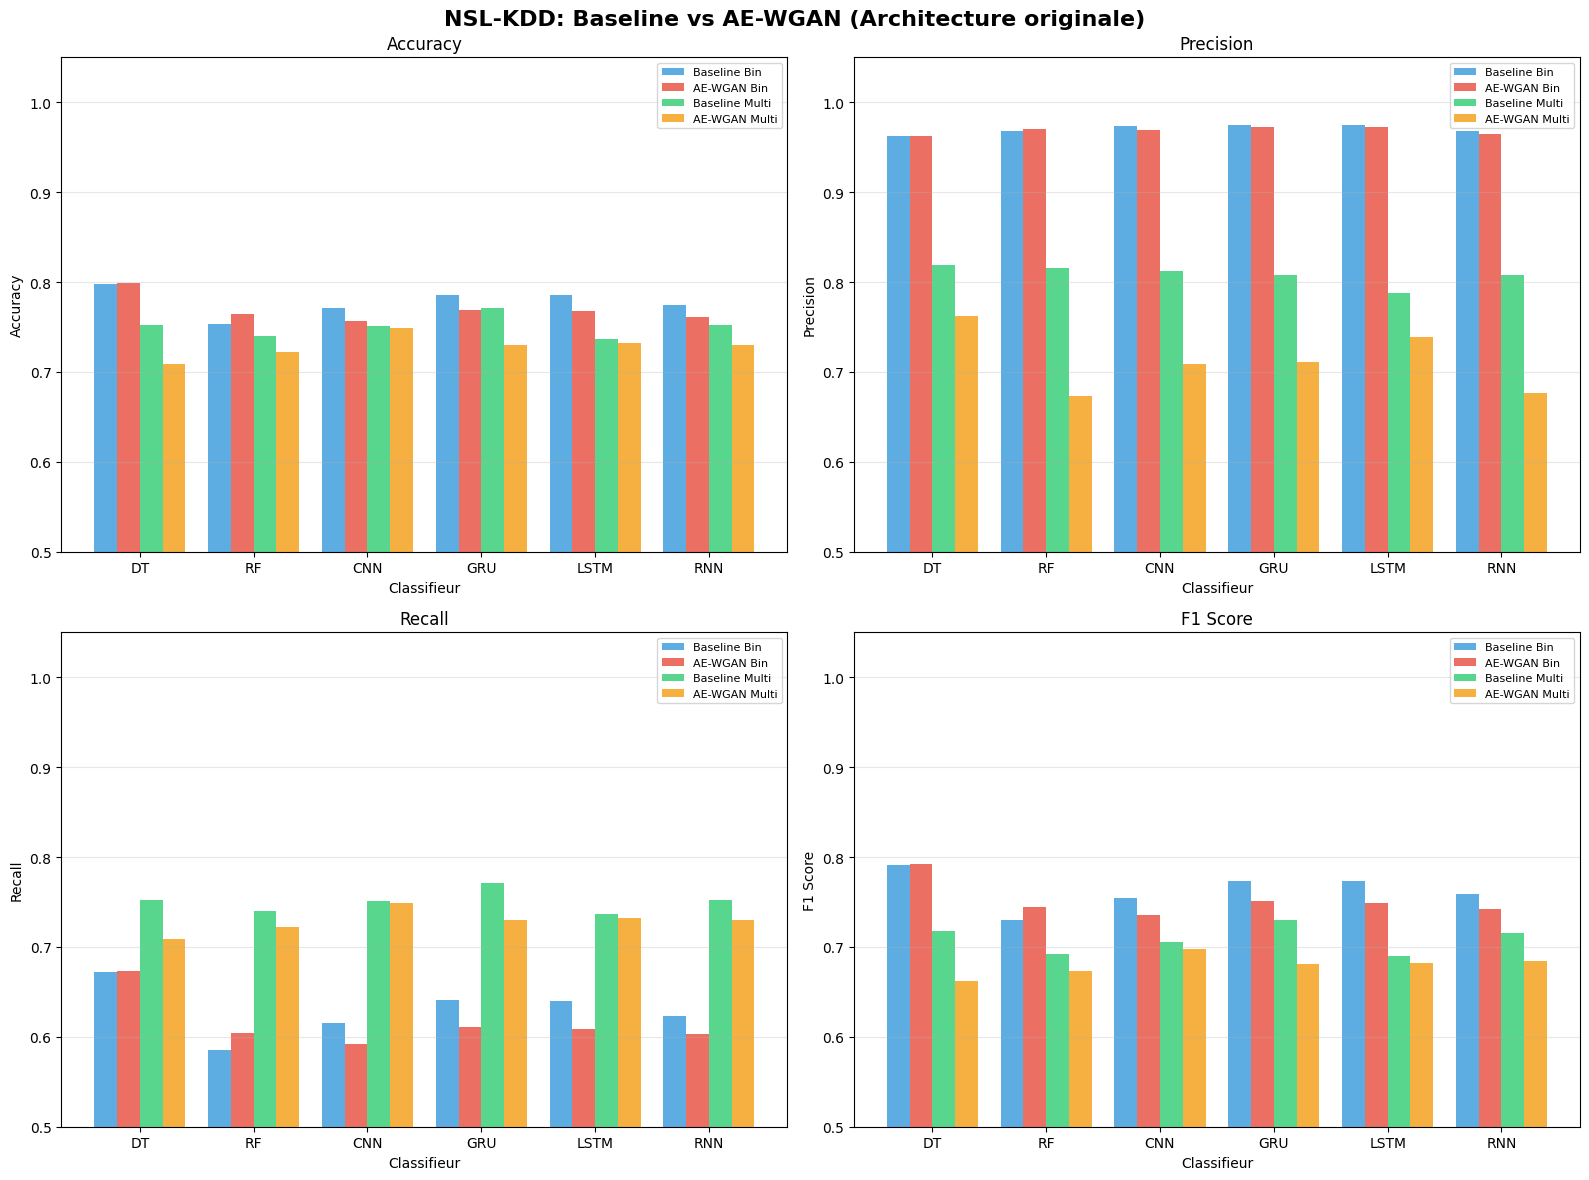

✅ Graphique sauvegardé


In [11]:
# Visualization
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('NSL-KDD: Baseline vs AE-WGAN (Architecture originale)', fontsize=16, fontweight='bold')
metrics = ['accuracy','precision','recall','f1_score']
titles = ['Accuracy','Precision','Recall','F1 Score']
for idx, (metric, title) in enumerate(zip(metrics, titles)):
    ax = axes[idx//2][idx%2]
    clfs = [r['classifier'] for r in baseline_binary]
    x = np.arange(len(clfs)); w = 0.2
    ax.bar(x-1.5*w, [r[metric] for r in baseline_binary], w, label='Baseline Bin', color='#3498db', alpha=0.8)
    ax.bar(x-0.5*w, [r[metric] for r in enhanced_binary], w, label='AE-WGAN Bin', color='#e74c3c', alpha=0.8)
    ax.bar(x+0.5*w, [r[metric] for r in baseline_multi], w, label='Baseline Multi', color='#2ecc71', alpha=0.8)
    ax.bar(x+1.5*w, [r[metric] for r in enhanced_multi], w, label='AE-WGAN Multi', color='#f39c12', alpha=0.8)
    ax.set_xlabel('Classifieur'); ax.set_ylabel(title); ax.set_title(title)
    ax.set_xticks(x); ax.set_xticklabels(clfs)
    ax.legend(fontsize=8); ax.set_ylim(0.5,1.05); ax.grid(axis='y',alpha=0.3)
plt.tight_layout()
plt.savefig('results_original_architecture.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Graphique sauvegardé")

In [12]:
# CSV Export
all_results = []
for r in baseline_binary: all_results.append({**r, 'type':'Baseline', 'classification':'Binary'})
for r in enhanced_binary: all_results.append({**r, 'type':'AE-WGAN', 'classification':'Binary'})
for r in baseline_multi: all_results.append({**r, 'type':'Baseline', 'classification':'Multiclass'})
for r in enhanced_multi: all_results.append({**r, 'type':'AE-WGAN', 'classification':'Multiclass'})

df_results = pd.DataFrame(all_results)
df_results.to_csv('results_original_architecture.csv', index=False)
print("\n✅ Résultats sauvegardés: results_original_architecture.csv")
print(df_results.to_string(index=False))

# Télécharger
import shutil
shutil.copy('results_original_architecture.csv', '/content/drive/MyDrive/')
shutil.copy('results_original_architecture.png', '/content/drive/MyDrive/')
print("✅ Copié sur Google Drive")


✅ Résultats sauvegardés: results_original_architecture.csv
classifier  accuracy  precision   recall  f1_score     type classification
        DT  0.798306   0.962595 0.671784  0.791317 Baseline         Binary
        RF  0.753149   0.968058 0.585678  0.729815 Baseline         Binary
       CNN  0.771380   0.973369 0.615211  0.753915 Baseline         Binary
       GRU  0.786063   0.975202 0.640458  0.773153 Baseline         Binary
      LSTM  0.785797   0.974846 0.640224  0.772871 Baseline         Binary
       RNN  0.773953   0.968171 0.623393  0.758438 Baseline         Binary
        DT  0.798705   0.962323 0.672719  0.791873  AE-WGAN         Binary
        RF  0.764017   0.970562 0.603756  0.744427  AE-WGAN         Binary
       CNN  0.757186   0.968786 0.592535  0.735325  AE-WGAN         Binary
       GRU  0.768763   0.972353 0.611159  0.750562  AE-WGAN         Binary
      LSTM  0.767654   0.972855 0.608821  0.748946  AE-WGAN         Binary
       RNN  0.761444   0.964255 0.603288